# SC Engagement List - Exploratory Data Analysis
Profiling `SC Engagement List2026-10-07 07_48_09.xlsx` before using it in the disengagement / ramp-to-5 analysis (`SC_disengagement.ipynb`).

Each row is one **engagement** (a staff member's stint at a client shortcode).

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)

BLUE = '#2a78d6'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.grid.axis': 'y',
    'figure.figsize': (10, 3.5),
})

In [2]:
data_path = Path(r"C:\Users\Alfonso(FonsoP)Panli\Desktop\Projects\Disengagement\Data")
sc_engagement_raw = pd.read_excel(data_path / 'SC Engagement List2026-10-07 07_48_09.xlsx')

# Use the extract date (not today) for open engagements so results are reproducible
EXTRACT_DATE = pd.Timestamp('2026-10-07')

## 1. Shape, types, missing values

In [3]:
df = sc_engagement_raw.copy()
print(df.shape)
df.head()

(30837, 14)


,Username,CSID,User Status,First Name,Middle Name,Last Name,Employment Status,Category,Engagement ID,Client Name,Shortcode,Engagement Status,Engagement Date,Disengagement Date
0,AakashM@cloudstaff.com,CS-15237,active,akash,NaN,mallick,Contractual,Engaged,CS-15237-01,Huffman Group LLC,NXTLEVELDM,engage,2026-05-04,NaN
1,AakashR@cloudstaff.com,CS-12502,inactive,aakash,NaN,rai,Separated,RTG,CS-12502-01,4Stones LLC dba Coburn and Company,COBURNANDCO,disengage,2024-03-18,2025-04-11
2,AakashR@cloudstaff.com,CS-12502,inactive,aakash,NaN,rai,Separated,RTG,CS-12502-02,Disengaged Staff Pool,CSTREENGAGE,disengage,2025-04-12,2025-05-10
3,aaroml@cloudstaff.com,CS-01271,inactive,aarom paul,cajucom,laus,Resigned,Engaged,CS-01271-01,Temenos Australia Services Pty Ltd,CIB019,disengage,2016-11-29,2018-03-02
4,aarona@cloudstaff.com,CS-04424,inactive,aaron gilbert,salta,alfonzo,Separated,RTG,CS-04424-01,Stafflink Pty Ltd,STAFFLINK,disengage,2019-08-07,2020-04-17


In [4]:
profile = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_null': df.isna().sum(),
    'pct_null': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(),
    'example': df.iloc[0],
})
profile

,dtype,n_null,pct_null,n_unique,example
Username,str,0,0.00,19028,AakashM@cloudstaff.com
CSID,str,0,0.00,19515,CS-15237
User Status,str,0,0.00,4,active
First Name,str,0,0.00,11823,akash
Middle Name,str,1544,5.01,7478,NaN
Last Name,str,0,0.00,7765,mallick
Employment Status,str,0,0.00,13,Contractual
Category,str,0,0.00,6,Engaged
Engagement ID,str,0,0.00,30831,CS-15237-01
Client Name,str,0,0.00,2484,Huffman Group LLC


In [4]:
print('Fully duplicated rows:', df.duplicated().sum())
print('Duplicated Engagement IDs:', df['Engagement ID'].duplicated().sum())
df[df['Engagement ID'].duplicated(keep=False)].sort_values('Engagement ID')

Fully duplicated rows: 1
Duplicated Engagement IDs: 6


,Username,CSID,User Status,First Name,Middle Name,Last Name,Employment Status,Category,Engagement ID,Client Name,Shortcode,Engagement Status,Engagement Date,Disengagement Date
19526,lourdinoc@cloudstaff.com,CS-03724,inactive,lourdino,macawili,capati,Separated,RTG,CS-03724-02,Disengaged Staff Pool,CSTREENGAGE,disengage,2022-03-20,2022-03-29
19527,lourdinoc@cloudstaff.com,CS-03724,inactive,lourdino,macawili,capati,Separated,RTG,CS-03724-02,NicomIT Solutions Inc.,NICOMIT,disengage,2022-03-30,2022-09-18
8411,emsb@cloudstaff.com,CS-05609,inactive,noeme,acala,bacolcol,Resigned,RTG,CS-05609-04,Disengaged Staff Pool,CSTREENGAGE,disengage,2022-03-26,2022-03-27
8413,emsb@cloudstaff.com,CS-05609,inactive,noeme,acala,bacolcol,Resigned,RTG,CS-05609-04,Resile Pty Ltd,RESILE,disengage,2022-04-04,2022-09-23
4244,cassyp@cloudstaff.com,CS-08257,inactive,catherine,lucas,parungao,Resigned,Engaged,CS-08257-02,Disengaged Staff Pool,CSTREENGAGE,disengage,2022-03-26,2022-03-27
4246,cassyp@cloudstaff.com,CS-08257,inactive,catherine,lucas,parungao,Resigned,Engaged,CS-08257-02,Resile Pty Ltd,RESILE,disengage,2022-04-04,2022-11-17
4351,cathyv@cloudstaff.com,CS-08956,inactive,catherine,gonzales,velecina,AWOL,Engaged,CS-08956-01,Valiant Finance Pty Ltd,VALIANT,disengage,2022-04-04,2022-07-21
4352,cathyv@cloudstaff.com,CS-08956,inactive,catherine,gonzales,velecina,AWOL,Engaged,CS-08956-01,Valiant Finance Pty Ltd,VALIANT,disengage,2022-04-18,2022-08-08
28250,SherwinR@cloudstaff.com,CS-20122,inactive,sherwin mico,zabala,ramos,Resigned,RTG,CS-20122-05,Disengaged Staff Pool,CSTREENGAGE,disengage,2022-02-03,2022-02-13
28251,SherwinR@cloudstaff.com,CS-20122,inactive,sherwin mico,zabala,ramos,Resigned,RTG,CS-20122-05,Little Real Estate (Vic & NSW) Pty Ltd,LRE,disengage,2022-02-14,2025-07-15


## 2. Categorical columns

In [5]:
for col in ['Engagement Status', 'Category', 'Employment Status', 'User Status']:
    vc = df[col].value_counts(dropna=False)
    display(pd.DataFrame({'count': vc, 'pct': (vc / len(df) * 100).round(1)}).rename_axis(col))

,count,pct
Engagement Status,,
disengage,23313,75.6
engage,7461,24.2
bench,63,0.2


,count,pct
Category,,
Engaged,18191,59.0
RTG,9924,32.2
Hub,2648,8.6
Support-OLD,58,0.2
TLO,15,0.0
Trainees,1,0.0


,count,pct
Employment Status,,
Resigned,12412,40.3
Regular,8236,26.7
Separated,5647,18.3
Probationary,1099,3.6
End-of-Contract,1042,3.4
TLO,781,2.5
AWOL,680,2.2
Cancelled Employment,399,1.3
Contractual,281,0.9


,count,pct
User Status,,
inactive,20366,66.0
active,9511,30.8
passive,959,3.1
pending,1,0.0


In [6]:
# Engagement Status should line up with whether there is a Disengagement Date
pd.crosstab(df['Engagement Status'], df['Disengagement Date'].isna().map({True: 'no end date', False: 'has end date'}))

Disengagement Date,has end date,no end date
Engagement Status,,
bench,63,0
disengage,23296,17
engage,0,7461


In [8]:
pd.crosstab(df['Category'], df['Engagement Status'], margins=True)

Engagement Status,bench,disengage,engage,All
Category,,,,
Engaged,8,11715,6468,18191
Hub,1,1872,775,2648
RTG,44,9662,218,9924
Support-OLD,6,52,0,58
TLO,4,11,0,15
Trainees,0,1,0,1
All,63,23313,7461,30837


In [7]:
# Employment Status is the person's *current* status, not the status of this engagement
# (e.g. 'Regular' staff with ended engagements were moved to another client)
pd.crosstab(df['Employment Status'], df['Engagement Status'], margins=True)

Engagement Status,bench,disengage,engage,All
Employment Status,,,,
AWOL,0,680,0,680
Cancelled Employment,0,395,4,399
Contractual,0,74,207,281
Dismissed,0,86,2,88
End of Probation,0,33,2,35
End-of-Contract,0,1041,1,1042
End-of-Project,0,117,0,117
Part-Time,0,7,13,20
Probationary,0,48,1051,1099


## 3. Dates

In [8]:
df['engagement_date'] = pd.to_datetime(df['Engagement Date'], errors='coerce')
df['disengagement_date'] = pd.to_datetime(df['Disengagement Date'], errors='coerce')

print('Unparseable engagement dates:', df['engagement_date'].isna().sum())
print('Unparseable disengagement dates (non-blank raw):',
      (df['disengagement_date'].isna() & df['Disengagement Date'].notna()).sum())
print('Engagement date range:   ', df['engagement_date'].min().date(), '->', df['engagement_date'].max().date())
print('Disengagement date range:', df['disengagement_date'].min().date(), '->', df['disengagement_date'].max().date())

Unparseable engagement dates: 0
Unparseable disengagement dates (non-blank raw): 0
Engagement date range:    1995-05-13 -> 2026-10-08
Disengagement date range: 2014-12-31 -> 2026-10-07


In [11]:
yearly = pd.DataFrame({
    'engagements': df['engagement_date'].dt.year.value_counts(),
    'disengagements': df['disengagement_date'].dt.year.value_counts(),
}).sort_index().fillna(0).astype(int)
yearly.index = yearly.index.astype(int)
yearly['net'] = yearly['engagements'] - yearly['disengagements']
yearly

,engagements,disengagements,net
1995,1,0,1
2009,1,0,1
2010,3,0,3
2011,4,0,4
2012,9,0,9
2013,27,0,27
2014,129,1,128
2015,379,64,315
2016,708,395,313
2017,830,428,402


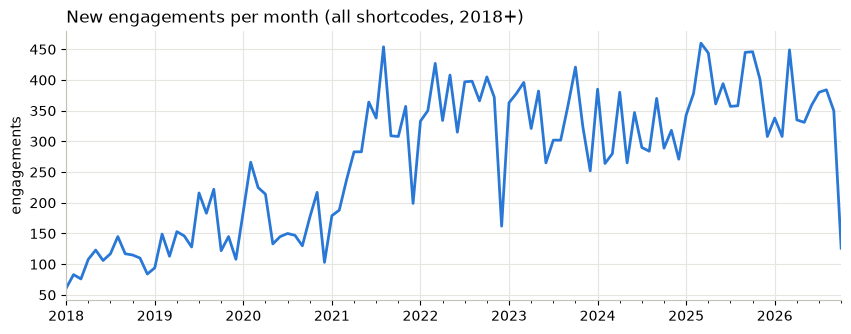

In [9]:
monthly_starts = df.set_index('engagement_date').sort_index().loc['2018':].resample('MS').size()
ax = monthly_starts.plot(color=BLUE, linewidth=2)
ax.set_title('New engagements per month (all shortcodes, 2018+)', loc='left')
ax.set_xlabel(''); ax.set_ylabel('engagements')
plt.show()

In [10]:
df['tenure_days'] = (df['disengagement_date'] - df['engagement_date']).dt.days
df['tenure_days'].describe(percentiles=[.05, .1, .25, .5, .75, .9]).round(1)

count    23359.0
mean       348.5
std        478.2
min       -720.0
5%           3.0
10%         13.0
25%         45.0
50%        162.0
75%        461.0
90%        978.0
max       8146.0
Name: tenure_days, dtype: float64

## 4. Keys and relationships

In [11]:
per_csid = df.groupby('CSID').size()
print('Engagements per CSID:'); display(per_csid.describe().round(2))
display(per_csid.value_counts().sort_index().head(10).rename('n_csids'))

print('Usernames with >1 CSID (rehires?):', (df.groupby('Username')['CSID'].nunique() > 1).sum())
print('CSIDs with >1 Username:', (df.groupby('CSID')['Username'].nunique() > 1).sum())
print('Shortcodes with >1 Client Name:', (df.groupby('Shortcode')['Client Name'].nunique() > 1).sum())
print('Client Names with >1 Shortcode:', (df.groupby('Client Name')['Shortcode'].nunique() > 1).sum())
print('CSIDs with >1 active (engage) row:', (df[df['Engagement Status'] == 'engage'].groupby('CSID').size() > 1).sum())

Engagements per CSID:


count    19515.00
mean         1.58
std          1.13
min          1.00
25%          1.00
50%          1.00
75%          2.00
max         28.00
dtype: float64

1     13021
2      4120
3      1157
4       640
5       277
6       139
7        74
8        48
9        15
10       12
Name: n_csids, dtype: int64

Usernames with >1 CSID (rehires?): 458
CSIDs with >1 Username: 0
Shortcodes with >1 Client Name: 0
Client Names with >1 Shortcode: 0
CSIDs with >1 active (engage) row: 8


In [15]:
# Gap between consecutive engagements of the same CSID (open engagements end at EXTRACT_DATE)
seq = df.assign(end=df['disengagement_date'].fillna(EXTRACT_DATE)).sort_values(['CSID', 'engagement_date'])
seq['gap_days'] = (seq['engagement_date'] - seq.groupby('CSID')['end'].shift()).dt.days
print('Overlapping engagements (start before previous end):', (seq['gap_days'] < 0).sum())
seq['gap_days'].describe().round(1)

Overlapping engagements (start before previous end): 251


count    11322.0
mean        -4.7
std         78.3
min      -1855.0
25%          1.0
50%          1.0
75%          1.0
max       1408.0
Name: gap_days, dtype: float64

## 5. Internal vs client shortcodes
A large share of rows are internal Cloudstaff departments or pools (e.g. `CSTREENGAGE` = Disengaged Staff Pool). These need excluding before measuring client ramp-up.

Rule: client name starts with the word `CS` (internal departments, e.g. *CS Academy*, *CSDEVS Platform*), or contains *Cloudstaff* / *Disengaged Staff Pool*. Shortcode prefix alone is unreliable - a few `CSS*` codes belong to non-CS client names.

In [16]:
internal_pattern = r'^(?:CS\b|CSDEVS)|Cloudstaff|Disengaged Staff Pool'
df['is_internal'] = df['Client Name'].str.contains(internal_pattern, regex=True, na=False)

internal_summary = (df[df['is_internal']].groupby(['Shortcode', 'Client Name']).size()
                    .sort_values(ascending=False).rename('rows'))
print(f"Internal rows: {df['is_internal'].sum():,} ({df['is_internal'].mean():.1%}) across {len(internal_summary)} shortcodes")
internal_summary.head(20)

Internal rows: 9,837 (31.9%) across 98 shortcodes


Shortcode       Client Name                
CSTREENGAGE     Disengaged Staff Pool          5395
CLOUDSTAFF      Cloudstaff Philippines Inc.    2303
CSNOW           Cloudstaff Now                  255
CSTALENTOPS     CS Talent Operations            170
CSIMB           CS Research (IMB)               129
CSACADEMY       CS Academy                      111
CSAPAC          CS APAC Asia Pacific             77
CSENDP          CS Endpoint                      73
CSCONCIERGE     CS Concierge                     66
CSFRLNCR        CS Freelancer                    60
CSAMER          CS AMERICAS                      58
CSDEVSTAFFX     CS Dev Staff                     51
CSMKTG          CS Marketing                     49
CSOPTICORE      CS optiBPO Core                  46
CSACREC         CS Account Receivables           43
CSDEVCUSTOMERX  CS Dev Customer                  40
CSBIZSALES      CS Business Sales                38
CSDEVCOREOPX    CS Dev Core                      36
CSONBOARD       CS O

In [17]:
# Sanity check: CS-prefixed shortcodes NOT flagged as internal - review these manually
df[df['Shortcode'].str.startswith('CS', na=False) & ~df['is_internal']].groupby(['Shortcode', 'Client Name']).size()

Shortcode   Client Name             
CSSARTAR    ByteCraft Dynamics Ltd      1
CSSGENOG    GenoTech Systems            1
CSSHANAQ    StellarTech Creations       1
CSSJAMMARM  Jammar Holdings Ltd.        1
CSSKYLEM    KyleM Industries Inc.       1
CSSLEEW     Leeward Innovations Inc.    1
CSSLLOYDE   Lloyd Enterprises Ltd.      1
CSSPAULDO   Pauldo Dynamics Corp.       1
CSSSALLYS   SallyS Ventures LLC         1
dtype: int64

In [18]:
pd.crosstab(df['Category'], df['is_internal'].map({True: 'internal', False: 'client'}), margins=True)

is_internal,client,internal,All
Category,,,
Engaged,15540,2651,18191
Hub,428,2220,2648
RTG,5017,4907,9924
Support-OLD,5,53,58
TLO,10,5,15
Trainees,0,1,1
All,21000,9837,30837


## 6. Client concentration and tenure

In [19]:
clients = df[~df['is_internal']]
active = clients[clients['Engagement Status'] == 'engage']

top = pd.DataFrame({
    'total_engagements': clients['Shortcode'].value_counts(),
    'active_headcount': active['Shortcode'].value_counts(),
}).fillna(0).astype(int).sort_values('active_headcount', ascending=False)
top.head(20)

,total_engagements,active_headcount
Shortcode,,
ARRIVIA,1194,347
STAFFLINK,912,224
FINDEX,273,143
FOURTHENT,184,134
AVETTA,366,126
PARKSTREET,181,124
HALOMD,171,124
QUIKAID,284,119
ABRAMSON,290,105


Active client shortcodes: 1028


count    1028.0
mean        6.1
std        18.5
min         1.0
25%         1.0
50%         2.0
75%         5.0
90%        11.0
99%        87.8
max       347.0
dtype: float64

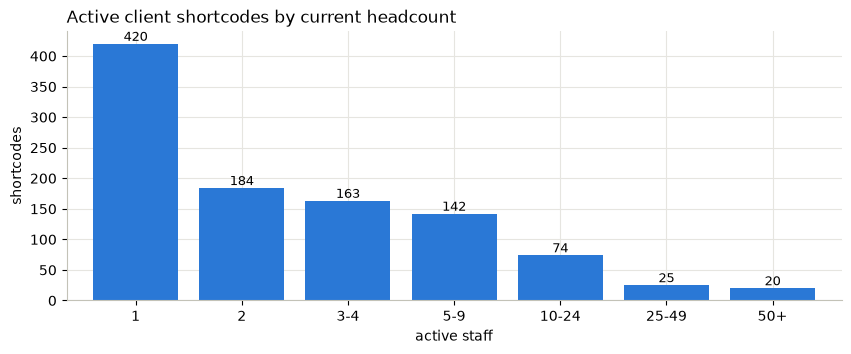

In [20]:
hc = active.groupby('Shortcode').size()
print('Active client shortcodes:', len(hc))
display(hc.describe(percentiles=[.25, .5, .75, .9, .99]).round(1))

bins = [0, 1, 2, 4, 9, 24, 49, np.inf]
labels = ['1', '2', '3-4', '5-9', '10-24', '25-49', '50+']
dist = pd.cut(hc, bins=bins, labels=labels).value_counts().reindex(labels)
ax = dist.plot.bar(color=BLUE, width=0.8, rot=0)
ax.set_title('Active client shortcodes by current headcount', loc='left')
ax.set_xlabel('active staff'); ax.set_ylabel('shortcodes')
for p, v in zip(ax.patches, dist.values):
    ax.annotate(f'{v:,}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.show()

count    14687.0
mean       456.1
std        509.6
min        -26.0
10%         30.0
25%         95.0
50%        270.0
75%        650.0
90%       1138.0
max       4558.0
Name: tenure_days, dtype: float64

Ended within 30 days:  10.0%
Ended within 90 days:  23.8%
Ended within 365 days: 58.3%


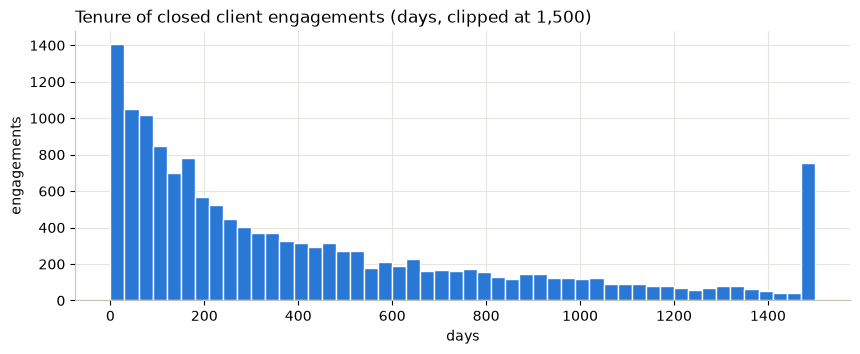

In [21]:
# Tenure at real clients (closed engagements only)
client_tenure = clients['tenure_days'].dropna()
display(client_tenure.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
print(f"Ended within 30 days:  {(client_tenure <= 30).mean():.1%}")
print(f"Ended within 90 days:  {(client_tenure <= 90).mean():.1%}")
print(f"Ended within 365 days: {(client_tenure <= 365).mean():.1%}")

ax = client_tenure.clip(lower=0, upper=1500).plot.hist(bins=50, color=BLUE, edgecolor='white', linewidth=1)
ax.set_title('Tenure of closed client engagements (days, clipped at 1,500)', loc='left')
ax.set_xlabel('days'); ax.set_ylabel('engagements')
plt.show()

## 7. Data quality flags

In [22]:
dq = pd.DataFrame(index=df.index)
dq['full_duplicate'] = df.duplicated(subset=sc_engagement_raw.columns.tolist())
dq['null_shortcode'] = df['Shortcode'].isna()
dq['disengaged_no_end_date'] = (df['Engagement Status'] == 'disengage') & df['disengagement_date'].isna()
dq['bench'] = df['Engagement Status'] == 'bench'
dq['future_start'] = df['engagement_date'] > EXTRACT_DATE
dq['end_before_start'] = df['disengagement_date'] < df['engagement_date']
dq['same_day_start_end'] = df['disengagement_date'] == df['engagement_date']
dq['start_before_2012'] = df['engagement_date'] < '2012-01-01'
dq['overlaps_prev_engagement'] = seq['gap_days'].reindex(df.index) < 0

dq_summary = dq.sum().rename('rows').to_frame()
dq_summary['rows_at_clients'] = dq[~df['is_internal']].sum()
dq_summary

,rows,rows_at_clients
full_duplicate,1,1
null_shortcode,7,7
disengaged_no_end_date,17,5
bench,63,26
future_start,57,56
end_before_start,35,21
same_day_start_end,414,289
start_before_2012,9,2
overlaps_prev_engagement,251,178


In [23]:
df[dq['disengaged_no_end_date']][['CSID', 'Shortcode', 'Employment Status', 'Engagement Date', 'Disengagement Date']]

,CSID,Shortcode,Employment Status,Engagement Date,Disengagement Date
3129,CS-21974,CSTREENGAGE,Separated,2025-08-16,NaN
3686,CS-23380,SCALEAPP,Separated,2025-08-04,NaN
3960,CS-02076,CSTREENGAGE,Regular,2025-09-13,NaN
4384,CS-08192,CSTREENGAGE,Separated,2024-11-25,NaN
7331,CS-12449,CSFRLNCR,End-of-Project,2024-02-21,NaN
8841,CS-13714,CSTREENGAGE,Separated,2025-02-25,NaN
9837,CS-24234,CSTREENGAGE,Separated,2026-03-10,NaN
11774,CS-11373,CSEXEC,Regular,2023-05-15,NaN
12564,CS-12025,POWERDRY,Separated,2023-10-23,NaN
12920,CS-23739,CSTREENGAGE,Separated,2025-11-05,NaN


In [24]:
df[dq['end_before_start']][['CSID', 'Shortcode', 'Engagement Status', 'Engagement Date', 'Disengagement Date']]

,CSID,Shortcode,Engagement Status,Engagement Date,Disengagement Date
2387,CS-00520,CLOUDSTAFF,disengage,2016-03-02,2016-01-17
2388,CS-00520,KINNECT,disengage,2018-07-13,2018-07-06
3057,CS-00846,CLOUDSTAFF,disengage,2016-07-18,2016-06-22
3058,CS-00846,CIB040,disengage,2016-07-18,2016-06-22
3267,CS-02332,CIB187,disengage,2018-03-21,2018-03-20
4144,CS-02427,ICE,disengage,2018-04-25,2018-04-24
4169,CS-02532,CIB201,disengage,2018-08-16,2018-08-03
4255,CS-02003,OIL,disengage,2017-10-09,2017-10-08
4295,CS-00602,CLOUDSTAFFINC,disengage,2017-06-19,2015-06-30
5417,CS-02056,TSOL,disengage,2018-10-03,2018-09-18


## 8. Cleaned dataset for the ramp analysis
Drops internal shortcodes, bench rows, duplicates, null shortcodes, future starts, disengaged rows without an end date, and end-before-start rows. Open engagements end at `EXTRACT_DATE`.

In [25]:
drop_mask = (
    df['is_internal']
    | dq['bench'] | dq['full_duplicate'] | dq['null_shortcode']
    | dq['future_start'] | dq['disengaged_no_end_date'] | dq['end_before_start']
)

sc_clean = df[~drop_mask].copy()
sc_clean['disengagement_date'] = sc_clean['disengagement_date'].fillna(EXTRACT_DATE)
sc_clean['is_open'] = sc_clean['Engagement Status'] == 'engage'

print(f'Raw rows:   {len(df):,}')
print(f'Clean rows: {len(sc_clean):,}  ({len(sc_clean) / len(df):.1%} kept)')
print(f'Clients:    {sc_clean["Shortcode"].nunique():,}')
print(f'CSIDs:      {sc_clean["CSID"].nunique():,}')

Raw rows:   30,837
Clean rows: 20,885  (67.7% kept)
Clients:    2,375
CSIDs:      17,661


In [26]:
# Optional: save for use in SC_disengagement.ipynb
# sc_clean.to_parquet(data_path / 'sc_engagement_clean.parquet', index=False)